In [25]:
import os
import sys
sys.path.insert(0, os.getcwd() + "/../Python/cellular_cycle") #add a pathway to the model
#sys.path.insert(0, os.getcwd() + "/../Python/fit") #add a pathway to the fit functions

from Austin_proliferation_model_concentration_5 import model

import numpy as np
import pandas as pd
import random 
import umap as umap
import sobol_seq
from sklearn import decomposition
from sklearn.cluster import KMeans
from peakfinder import peakfinder
import sobol_seq
from call_cell_events import call_events
import fracprolif as fp


import seaborn as sns
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt


pysb_sampled_parameter_names = ["V_s2skp","V_Fp","k_M","k_EMY","k_CDF","k_CDS","k_ED","K_S","K_MY","K_DF","d_CD","k_P1", "k_P2", "K_CD", "k_E", "K_M", "K_CE", "V_2E2F", "K_2E2F", "k_RE", "kf1", "kf2", "kb", "kasbaxmbcl2", "kdsbaxmbcl2", "k1sbh3", "k2sbh3", "kdbh3", "kasbh3bcl2", "kdsbh3bcl2"]


In [5]:

pos_history = np.load(os.getcwd() + "/../Python/fit_data/pso/position_history.npy")
frac_prolif_parameters_pso = pd.read_pickle(os.getcwd() + "/../Python/fit_data/pso/all_parameters_pso.pkl")
frac_prolif_parameters_original_parameters = pd.read_pickle(os.getcwd() + "/../Python/fit_data/pso/parameters_original_parameters_pso.pkl")
frac_prolif_parameters_pso_initial_cell = pd.read_pickle(os.getcwd() + "/../Python/fit_data/pso/frac_prolif_parameters_pso_longer_sim.pkl") 




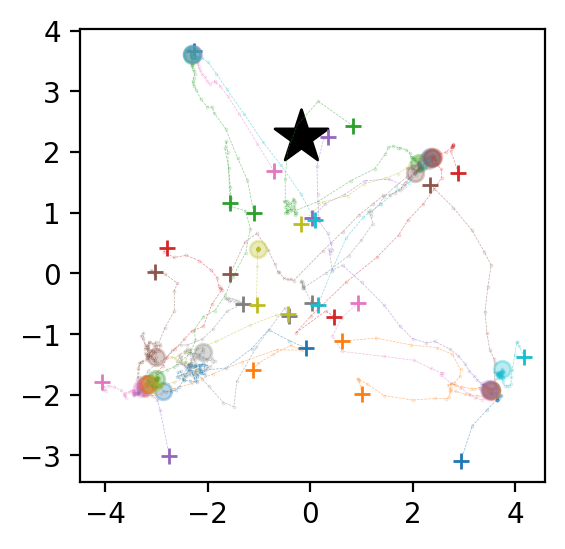

In [33]:
#fig 1
dim_reduction = 'umap'
dim_reduction = 'pca'

colors = [np.array([col_tmp]) for col_tmp in sns.color_palette(n_colors=np.shape(pos_history)[1])]

fig = plt.figure(figsize=(3,3),dpi=200)
ax = fig.add_subplot(111)
for chain in range(np.shape(pos_history)[1]) :
    x_tmp = frac_prolif_parameters_pso[frac_prolif_parameters_pso['particle']==chain][[dim_reduction + ' 1', dim_reduction + ' 2']].to_numpy()
    ax.scatter(x_tmp[:, 0], x_tmp[:, 1], c = colors[chain], alpha = 0.25,s = 0.1);
    ax.plot(x_tmp[:,0], x_tmp[:,1], c = colors[chain], alpha = 0.5, lw = 0.25, ls = '--');
    ax.plot(x_tmp[0,0], x_tmp[0,1],c=colors[chain], marker='+')
    ax.plot(x_tmp[-1,0], x_tmp[-1,1],c=colors[chain], marker='o',alpha=0.3)

x_tmp = frac_prolif_parameters_original_parameters[[dim_reduction + ' 1', dim_reduction + ' 2']].to_numpy()
ax.scatter(x_tmp[0,0], x_tmp[0,1],c='black', marker="*", s=400)


C:\Users\Grim.M\Anaconda3\lib\site-packages\seaborn\distributions.py:306: UserWarning: Dataset has 0 variance; skipping density estimate.
  warnings.warn(msg, UserWarning)
C:\Users\Grim.M\Anaconda3\lib\site-packages\seaborn\distributions.py:306: UserWarning: Dataset has 0 variance; skipping density estimate.
  warnings.warn(msg, UserWarning)
C:\Users\Grim.M\Anaconda3\lib\site-packages\seaborn\distributions.py:306: UserWarning: Dataset has 0 variance; skipping density estimate.
  warnings.warn(msg, UserWarning)
C:\Users\Grim.M\Anaconda3\lib\site-packages\seaborn\distributions.py:306: UserWarning: Dataset has 0 variance; skipping density estimate.
  warnings.warn(msg, UserWarning)
C:\Users\Grim.M\Anaconda3\lib\site-packages\seaborn\distributions.py:306: UserWarning: Dataset has 0 variance; skipping density estimate.
  warnings.warn(msg, UserWarning)
C:\Users\Grim.M\Anaconda3\lib\site-packages\seaborn\distributions.py:306: UserWarning: Dataset has 0 variance; skipping density estimate.
  

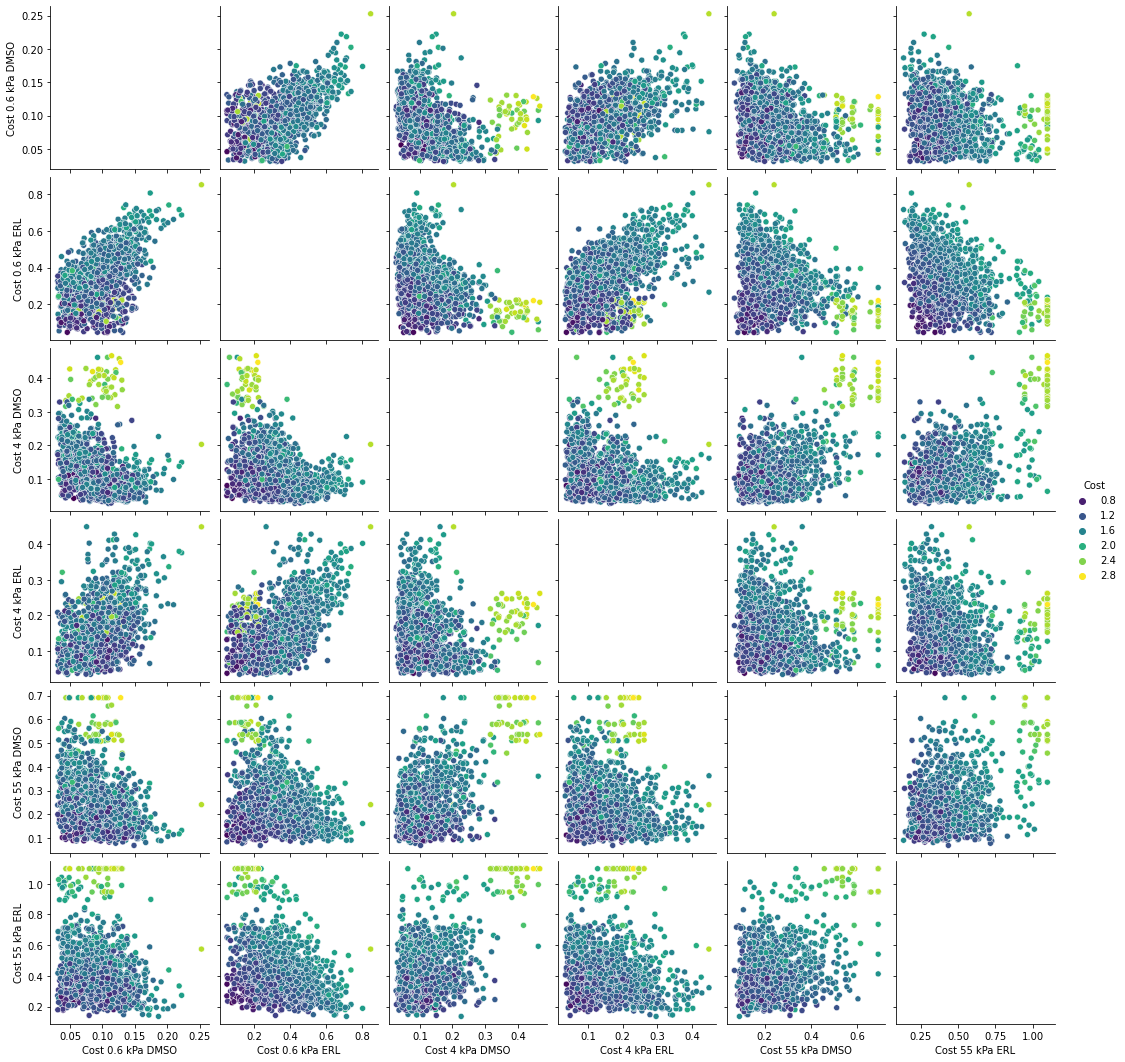

In [13]:

frac_prolif_parameters_pso.loc[frac_prolif_parameters_pso['Cost 0.6 kPa DMSO']==np.inf, 'Cost 0.6 kPa DMSO']= 4
frac_prolif_parameters_pso.loc[frac_prolif_parameters_pso['Cost 0.6 kPa ERL']==np.inf, 'Cost 0.6 kPa ERL']= 4

frac_prolif_parameters_pso.loc[frac_prolif_parameters_pso['Cost 4 kPa DMSO']==np.inf, 'Cost 4 kPa DMSO']= 4
frac_prolif_parameters_pso.loc[frac_prolif_parameters_pso['Cost 4 kPa ERL']==np.inf, 'Cost 4 kPa ERL']= 4

frac_prolif_parameters_pso.loc[frac_prolif_parameters_pso['Cost 55 kPa DMSO']==np.inf, 'Cost 55 kPa DMSO']= 4
frac_prolif_parameters_pso.loc[frac_prolif_parameters_pso['Cost 55 kPa ERL']==np.inf, 'Cost 55 kPa ERL']= 4

data_tmp = frac_prolif_parameters_pso[['Cost 0.6 kPa DMSO', 'Cost 0.6 kPa ERL', 'Cost 4 kPa DMSO', 'Cost 4 kPa ERL', 'Cost 55 kPa DMSO', 'Cost 55 kPa ERL', 'Cost']]

data_tmp = data_tmp[~data_tmp.isin([np.nan, np.inf, -np.inf]).any(1)]
sns.pairplot(data_tmp, hue= 'Cost',palette = 'viridis')

C:\Users\Grim.M\Anaconda3\lib\site-packages\ipykernel_launcher.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequenc

*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or R

*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.


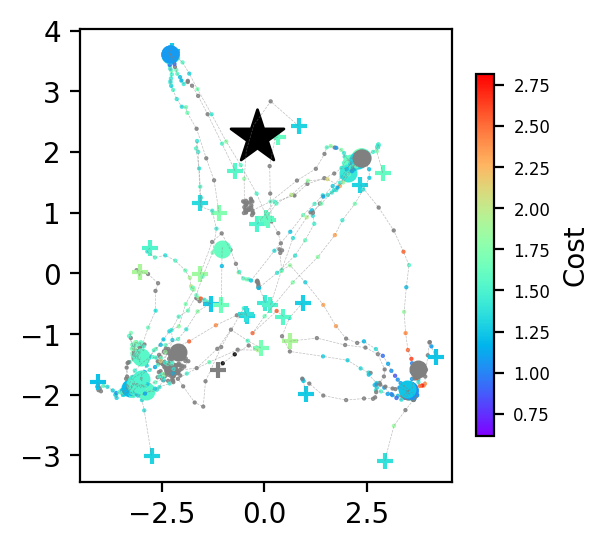

In [22]:

colormap = cm.rainbow
normalize = mcolors.Normalize(vmin = min(frac_prolif_parameters_pso["Cost"]), vmax = max(frac_prolif_parameters_pso["Cost"][frac_prolif_parameters_pso["Cost"]<np.inf]))

frac_prolif_parameters_pso['color'] = list(map(tuple, colormap(normalize(frac_prolif_parameters_pso['Cost']))))
frac_prolif_parameters_pso['color'][frac_prolif_parameters_pso['Cost'] == np.inf] = 'grey'


fig = plt.figure(figsize=(3,3),dpi=200)
ax = fig.add_subplot(111)

for chain in range(np.shape(pos_history)[1]) :
    x_tmp = frac_prolif_parameters_pso[frac_prolif_parameters_pso['particle']==chain][[dim_reduction + ' 1', dim_reduction + ' 2']].to_numpy()
    color_tmp = frac_prolif_parameters_pso[frac_prolif_parameters_pso['particle']==chain]['color'].values;

    ax.plot(x_tmp[:,0], x_tmp[:,1], c =  'grey', alpha = 0.5, lw = 0.25, ls = '--');
    ax.scatter(x_tmp[:, 0], x_tmp[:, 1], c = color_tmp, alpha = 0.9,s = 0.3);
    ax.scatter(x_tmp[0,0], x_tmp[0,1], c=color_tmp[0], marker='+', s=30);
    ax.scatter(x_tmp[-1,0], x_tmp[-1,1], c=color_tmp[-1], marker='o', s=30);

scalarmappaple = cm.ScalarMappable(norm=normalize, cmap=colormap)
scalarmappaple.set_array([])

cb = fig.colorbar(scalarmappaple, shrink=0.8)
cb.set_label(label='Cost', fontsize=10)
cb.ax.tick_params(labelsize=6)

x_tmp = frac_prolif_parameters_original_parameters[[dim_reduction + ' 1', dim_reduction + ' 2']].to_numpy()
ax.scatter(x_tmp[0,0], x_tmp[0,1],c='black', marker="*", s=400)


C:\Users\Grim.M\Anaconda3\lib\site-packages\ipykernel_launcher.py:8: MatplotlibDeprecationWarning: Support for passing numbers through unit converters is deprecated since 3.5 and support will be removed two minor releases later; use Axis.convert_units instead.
  


Text(0, 0.5, 'Cost')

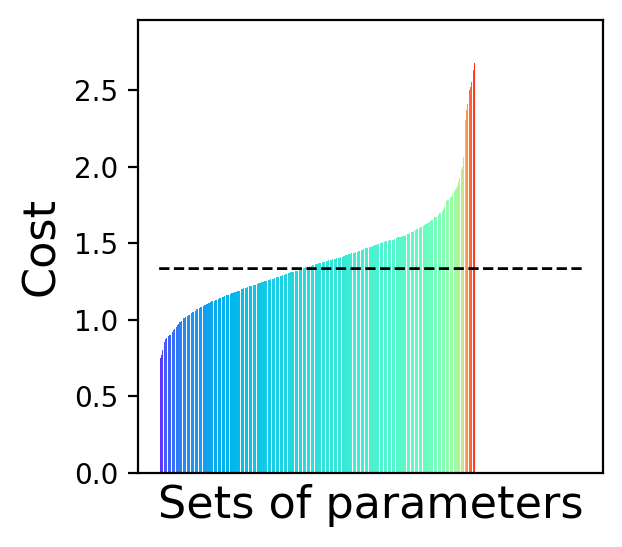

In [23]:

df = frac_prolif_parameters_pso[frac_prolif_parameters_pso['Cost']<np.inf][['index', 'Cost', 'particle', 'step']]
df = df.sort_values(by=['Cost'])

fig = plt.figure(figsize=(3,3),dpi=200)
ax = fig.add_subplot(111)
ax.bar(x='index', height='Cost', data=df, color=colormap(normalize(df.Cost.values)))
ax.set_xticklabels([]) 
ax.set_xticks([]) 
ax.plot([frac_prolif_parameters_original_parameters['Cost'][0] for n in range(len(frac_prolif_parameters_pso))], '--', color = 'black', linewidth=1) #original parameters

ax.set_xlabel('Sets of parameters', fontsize = 16)
ax.set_ylabel('Cost', fontsize = 16)


In [27]:
from sklearn.cluster import KMeans

n_clusters=8
kmeans = KMeans(n_clusters, random_state=0).fit(np.log10(frac_prolif_parameters_pso[pysb_sampled_parameter_names].to_numpy()))
kmeans.labels_
kmeans.cluster_centers_

frac_prolif_parameters_pso['cluster'] = kmeans.labels_
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, n_clusters)]
frac_prolif_parameters_pso['color cluster'] = [colors[cluster] for cluster in kmeans.labels_]

*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or R

0
1
2
3
4
5
6
7
8
9
10
11


*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or R

12
13
14
15
16
17
18
19
20
21
22
23


*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or R

24
25
26
27
28
29


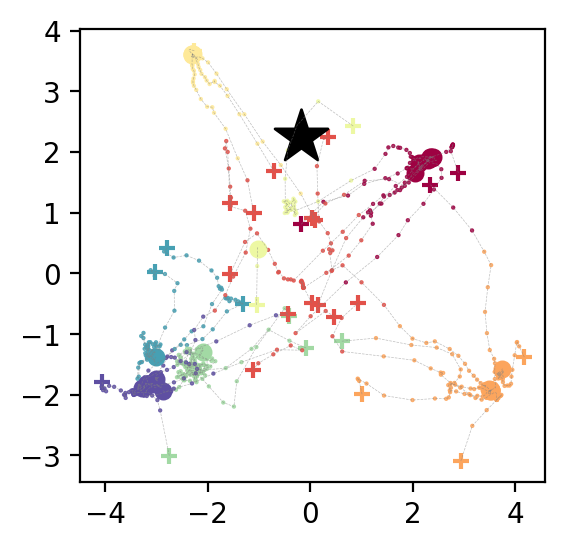

In [36]:
fig = plt.figure(figsize=(3,3),dpi=200)
ax = fig.add_subplot(111)

for chain in range(np.shape(pos_history)[1]) :
    print(chain)
    x_tmp = frac_prolif_parameters_pso[frac_prolif_parameters_pso['particle']==chain][[dim_reduction + ' 1', dim_reduction + ' 2']].to_numpy()
    color_tmp = np.array([np.array(col_tmp) for col_tmp in frac_prolif_parameters_pso[frac_prolif_parameters_pso['particle']==chain]['color cluster'].values])

    ax.plot(x_tmp[:,0], x_tmp[:,1], c =  'grey', alpha = 0.5, lw = 0.25, ls = '--');
    ax.scatter(x_tmp[:, 0], x_tmp[:, 1], c = color_tmp, alpha = 0.9,s = 0.3);
    ax.scatter(x_tmp[0,0], x_tmp[0,1], c=color_tmp[0], marker='+', s=30)
    ax.scatter(x_tmp[-1,0], x_tmp[-1,1], c=color_tmp[-1], marker='o', s=30)

x_tmp = frac_prolif_parameters_original_parameters[[dim_reduction + ' 1', dim_reduction + ' 2']].to_numpy()
ax.scatter(x_tmp[0,0], x_tmp[0,1],c='black', marker="*", s=400)

